# Tarea 5. Posible impacto de la Ley 2307 de 2023 en las tasas de crecimiento de la matrícula
**Entrada:** `dataset2.csv` (Tarea 2). Periodo: 2016_2017 a 2024_2025 ($n=9$ intervalos).

Para cada departamento y nivel se calcula el promedio histórico de los 7 intervalos previos a 2023,
$\bar g_{d,hist}=\frac{1}{7}\sum_{n=1}^{7} g_d[n]$,
y se seleccionan los casos en que **ambas** tasas posteriores lo superan: $g_d[8]>\bar g_{d,hist}$ y $g_d[9]>\bar g_{d,hist}$.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("figuras", exist_ok=True)
ds2 = pd.read_csv("dataset2.csv")
COLS = [c for c in ds2.columns if c not in ("departamento", "nivel")]
assert len(COLS) == 9
HIST = COLS[:7]              # 2016_2017 ... 2022_2023
P8, P9 = COLS[7], COLS[8]    # 2023_2024 y 2024_2025
NOMBRE = {"tecnica": "Técnica profesional", "tecnologica": "Tecnológica", "universitaria": "Universitaria"}
print("Histórico:", HIST[0], "→", HIST[-1], "| Posteriores:", P8, P9)

Histórico: 2016_2017 → 2022_2023 | Posteriores: 2023_2024 2024_2025


## 1–3. Promedio histórico y comparación

In [2]:
res = ds2[["departamento", "nivel"]].copy()
res["prom_hist"] = ds2[HIST].mean(axis=1)
res["tasa_2023_2024"] = ds2[P8]
res["tasa_2024_2025"] = ds2[P9]
res["dif_2023_2024"] = res["tasa_2023_2024"] - res["prom_hist"]
res["dif_2024_2025"] = res["tasa_2024_2025"] - res["prom_hist"]
res["dif_media"] = res[["dif_2023_2024", "dif_2024_2025"]].mean(axis=1)
res = res.round(2)

sel = (res[(res["dif_2023_2024"] > 0) & (res["dif_2024_2025"] > 0)]
       .sort_values(["nivel", "dif_media"], ascending=[True, False]).reset_index(drop=True))

print(f"Casos seleccionados: {len(sel)} de {len(res)} combinaciones departamento-nivel")
display(pd.DataFrame({"seleccionados": sel.groupby("nivel").size(),
                      "total": res.groupby("nivel").size()}).fillna(0).astype(int))
sel

Casos seleccionados: 45 de 93 combinaciones departamento-nivel


,seleccionados,total
nivel,,
tecnica,8,27
tecnologica,21,33
universitaria,16,33


,departamento,nivel,prom_hist,tasa_2023_2024,tasa_2024_2025,dif_2023_2024,dif_2024_2025,dif_media
0,Amazonas,tecnica,-44.76,-3.33,72.41,41.43,117.17,79.30
1,Nariño,tecnica,-12.16,-0.63,57.59,11.53,69.75,40.64
2,Córdoba,tecnica,-0.76,41.03,6.24,41.79,7.00,24.39
3,Caldas,tecnica,10.01,36.97,21.93,26.96,11.92,19.44
4,Huila,tecnica,-4.32,16.86,12.44,21.18,16.76,18.97
5,Santander,tecnica,-4.72,3.38,24.73,8.10,29.45,18.78
6,Valle del Cauca,tecnica,1.14,12.85,26.79,11.71,25.65,18.68
7,Risaralda,tecnica,6.72,12.30,8.14,5.58,1.42,3.50
8,Arauca,tecnologica,-7.00,7.31,37.04,14.31,44.04,29.17
9,Vaupés,tecnologica,-11.17,-8.51,25.58,2.66,36.75,19.71


## 4. Visualización

In [3]:
def sombrear_ley(ax):
    ax.axvspan(7.5, 9.5, color="tab:pink", alpha=0.25)
    ax.text(8.5, ax.get_ylim()[1], "Después\nde la Ley", ha="center", va="top", fontsize=8)

def graficar_top(nivel, top=3):
    """Combina los 'top' departamentos con mayor diferencia media en un solo gráfico (como el ejemplo del enunciado)."""
    s = sel[sel["nivel"] == nivel].head(top)
    if s.empty:
        print(f"{NOMBRE[nivel]}: ningún departamento cumple el criterio."); return
    fig, ax = plt.subplots(figsize=(8, 4.5))
    cols = plt.cm.tab10(np.arange(len(s)))
    for c, (_, r) in zip(cols, s.iterrows()):
        y = ds2[(ds2.departamento == r.departamento) & (ds2.nivel == nivel)][COLS].values.ravel()
        ax.plot(range(1, 10), y, "o-", color=c, label=r.departamento)
        ax.axhline(r.prom_hist, color=c, ls="--", lw=1, label=f"Prom. hist. {r.departamento}")
    ax.set_xticks(range(1, 10)); ax.grid(alpha=0.3)
    ax.set_title(f"{NOMBRE[nivel]}: top {len(s)} por diferencia con el promedio histórico")
    ax.set_xlabel("n (intervalo 2016–2017 a 2024–2025)"); ax.set_ylabel("Tasa de crecimiento (%)")
    sombrear_ley(ax); ax.legend(fontsize=7, loc="upper left")
    plt.tight_layout(); fig.savefig(f"figuras/t5_top_{nivel}.png", dpi=150); plt.show()

def graficar_todos(nivel, ncols=4):
    """Un panel por cada departamento seleccionado: tasa, línea horizontal del promedio histórico y zona posterior a la ley."""
    s = sel[sel["nivel"] == nivel]
    if s.empty:
        return
    nrows = int(np.ceil(len(s) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.2 * nrows), squeeze=False)
    for ax, (_, r) in zip(axes.ravel(), s.iterrows()):
        y = ds2[(ds2.departamento == r.departamento) & (ds2.nivel == nivel)][COLS].values.ravel()
        ax.plot(range(1, 10), y, "o-", color="tab:blue", label="Tasa de crecimiento")
        ax.axhline(r.prom_hist, color="red", ls="--", label="Promedio histórico")
        ax.axvspan(7.5, 9.5, color="tab:pink", alpha=0.25)
        ax.set_title(r.departamento, fontsize=9); ax.set_xticks(range(1, 10)); ax.grid(alpha=0.3)
    for ax in axes.ravel()[len(s):]:
        ax.axis("off")
    axes[0, 0].legend(fontsize=7)
    fig.suptitle(f"{NOMBRE[nivel]} – departamentos con g[8] y g[9] > promedio histórico", y=1.0)
    plt.tight_layout(); fig.savefig(f"figuras/t5_todos_{nivel}.png", dpi=130); plt.show()

### (a) Técnica profesional

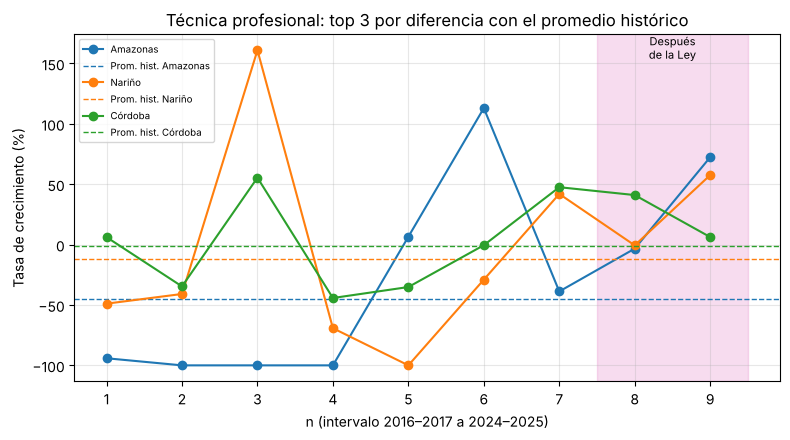

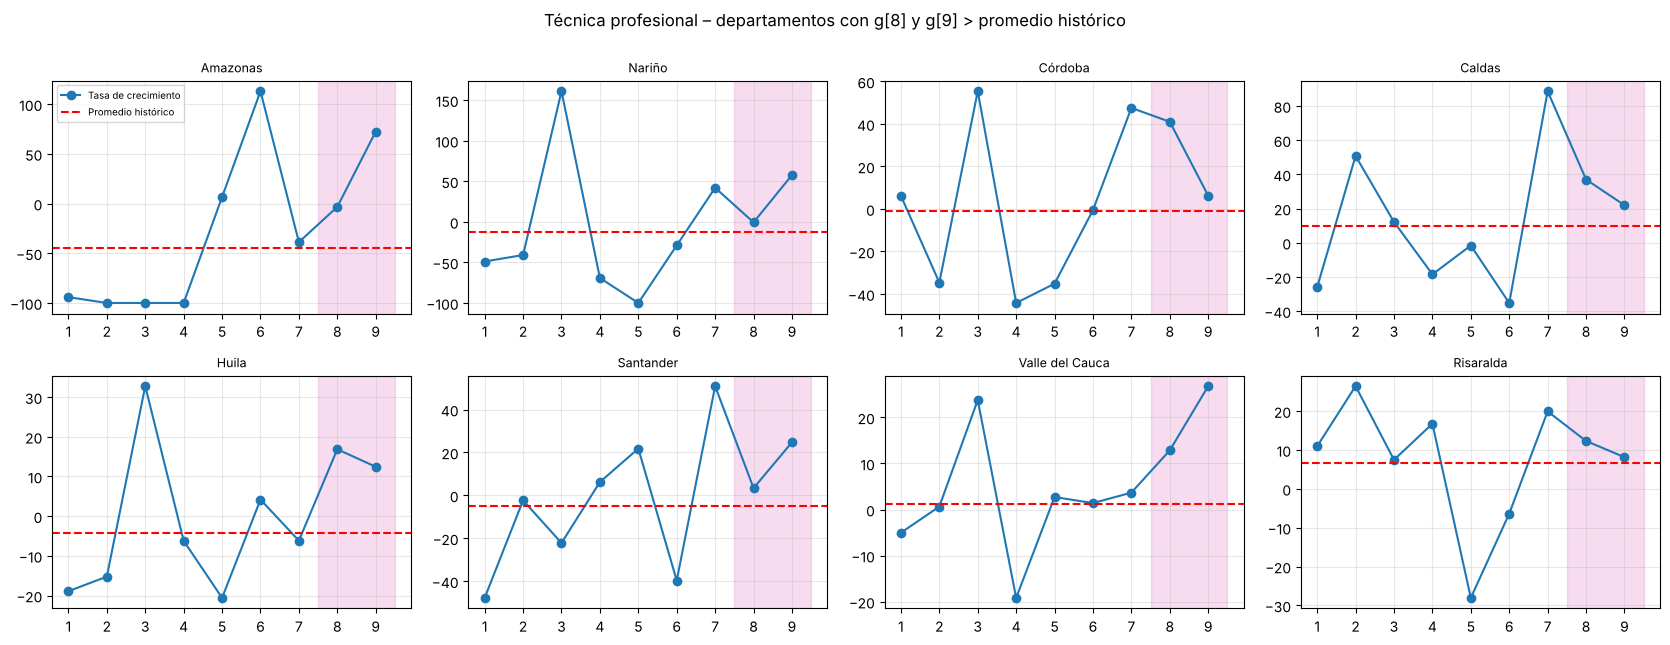

In [4]:
graficar_top("tecnica"); graficar_todos("tecnica")

### (b) Tecnológica

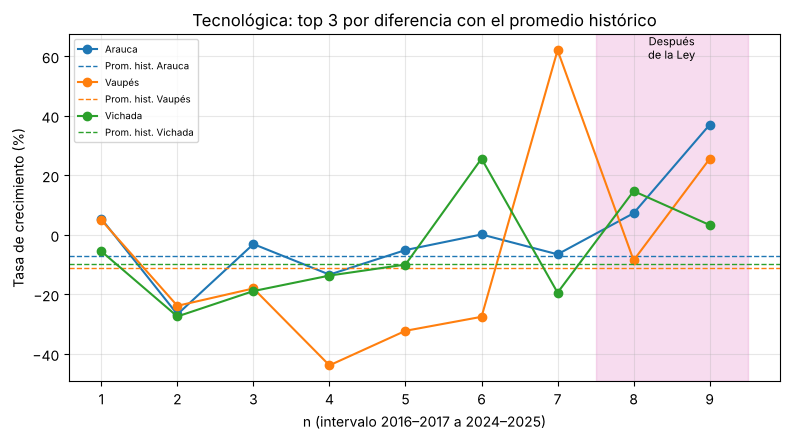

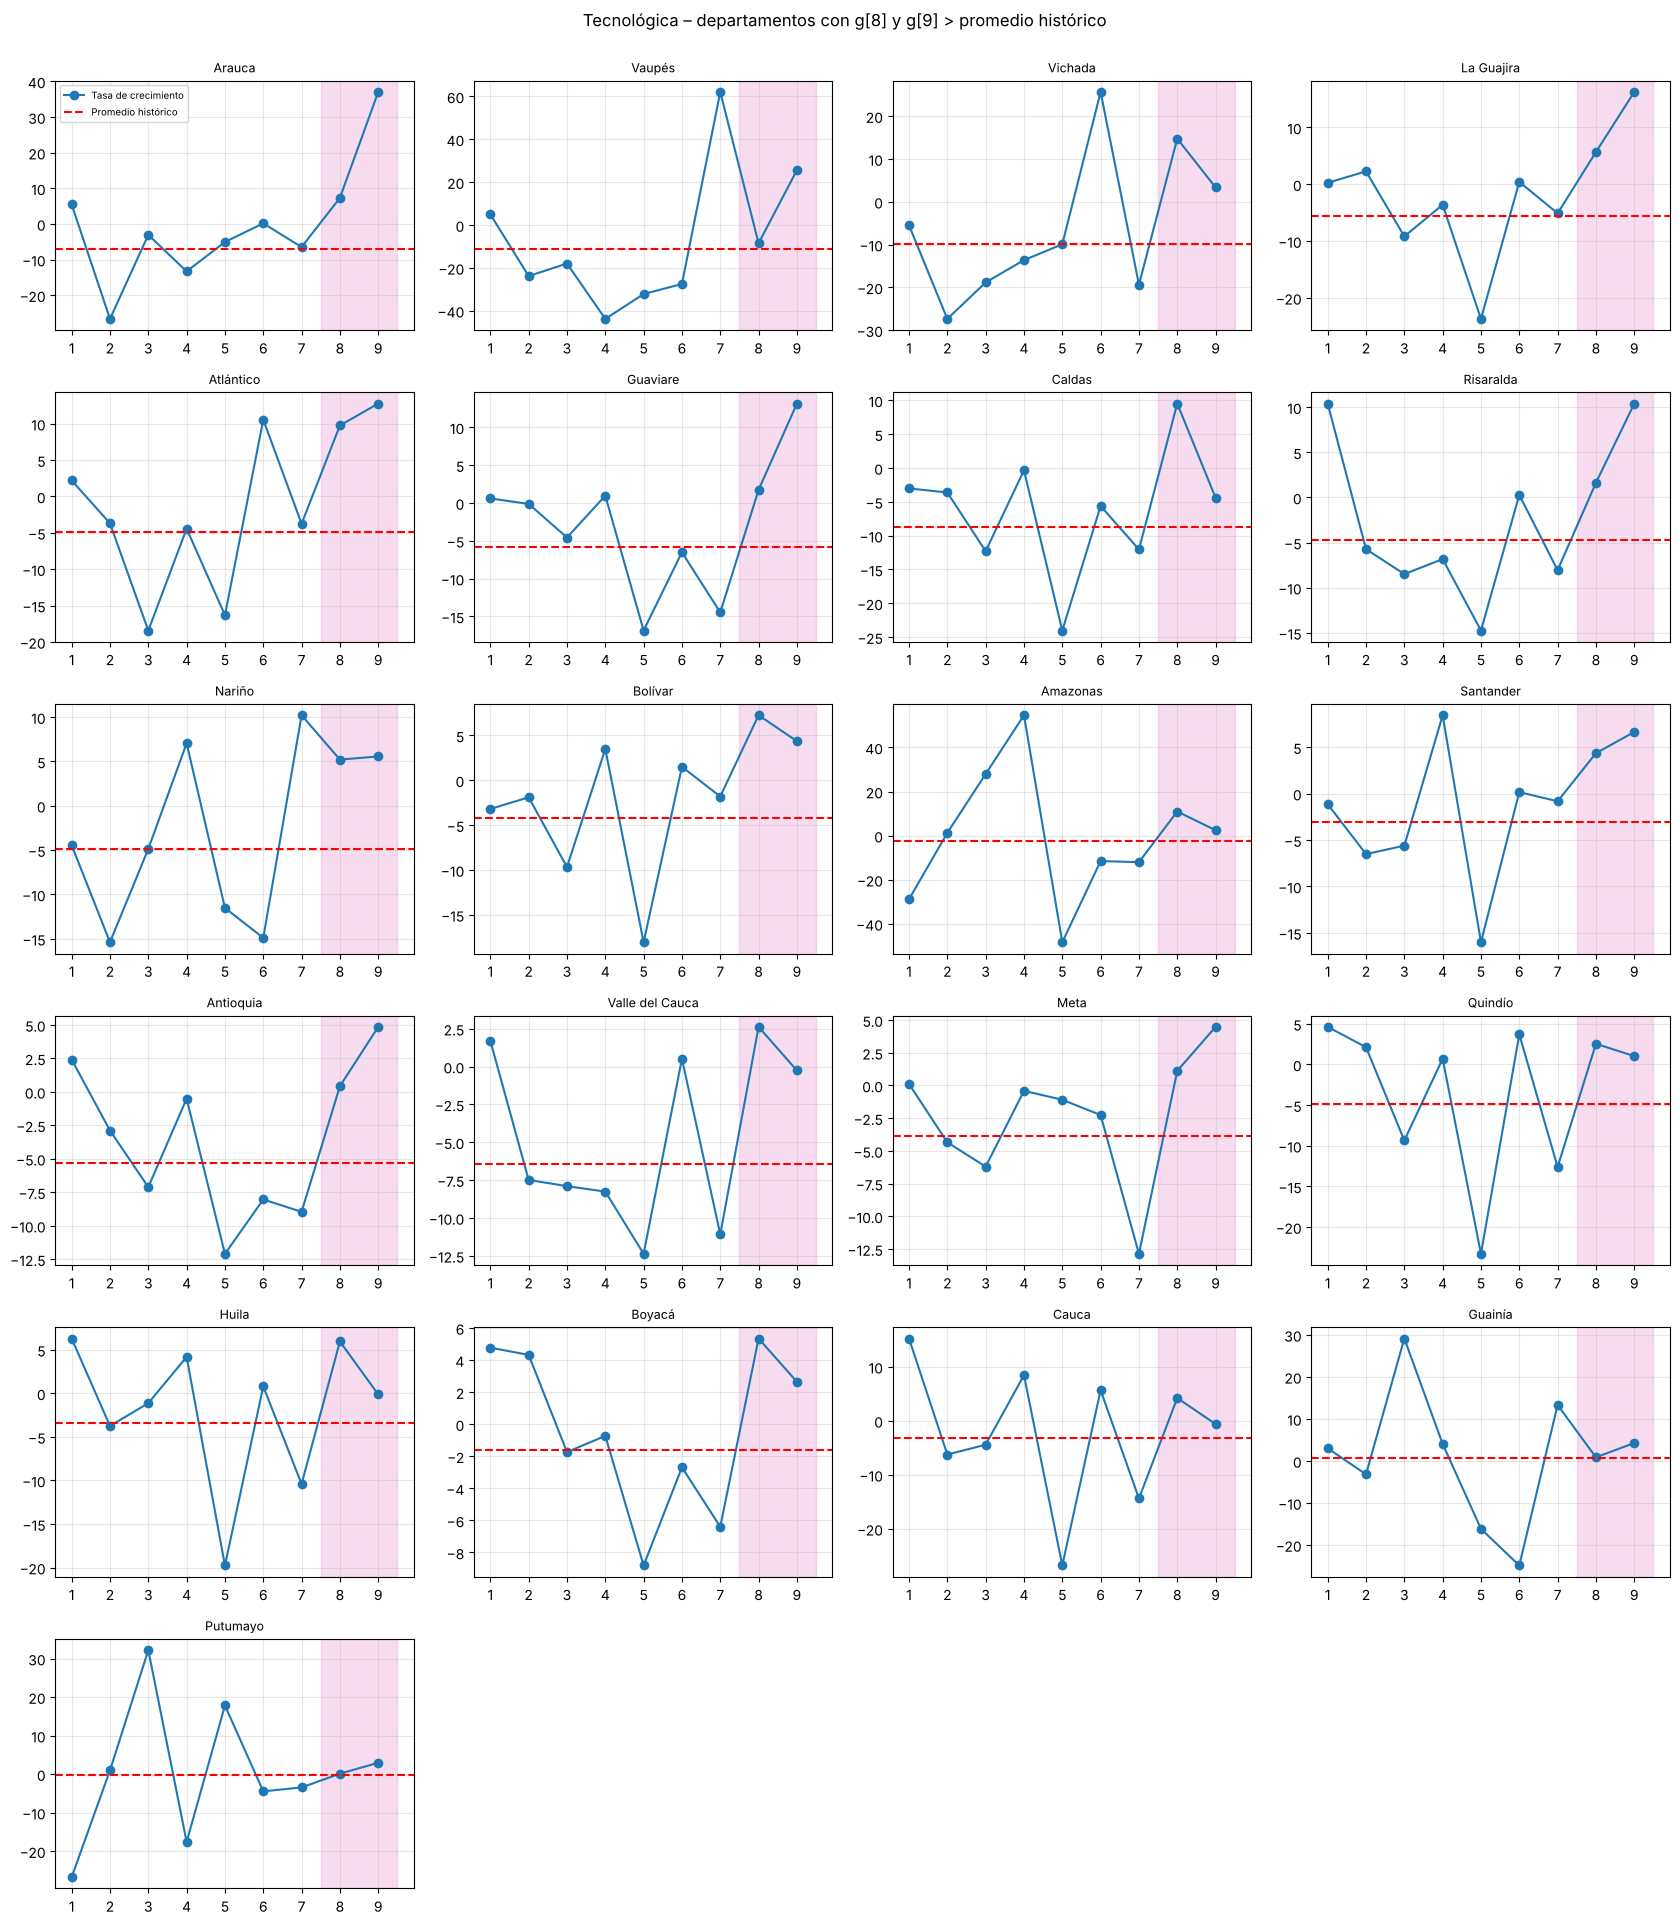

In [5]:
graficar_top("tecnologica"); graficar_todos("tecnologica")

### (c) Universitaria

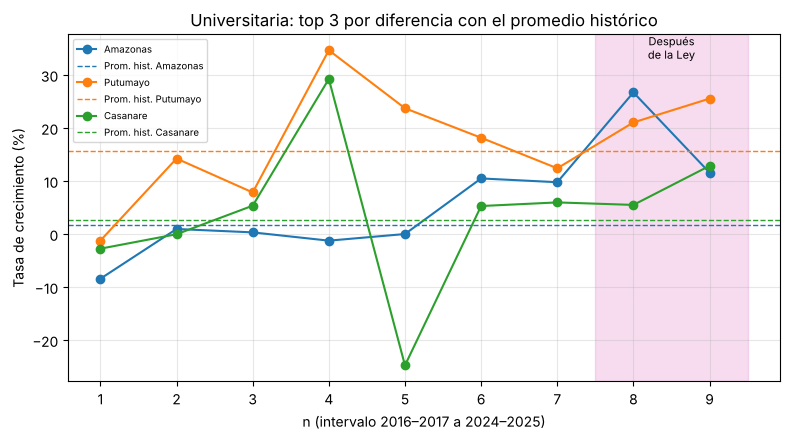

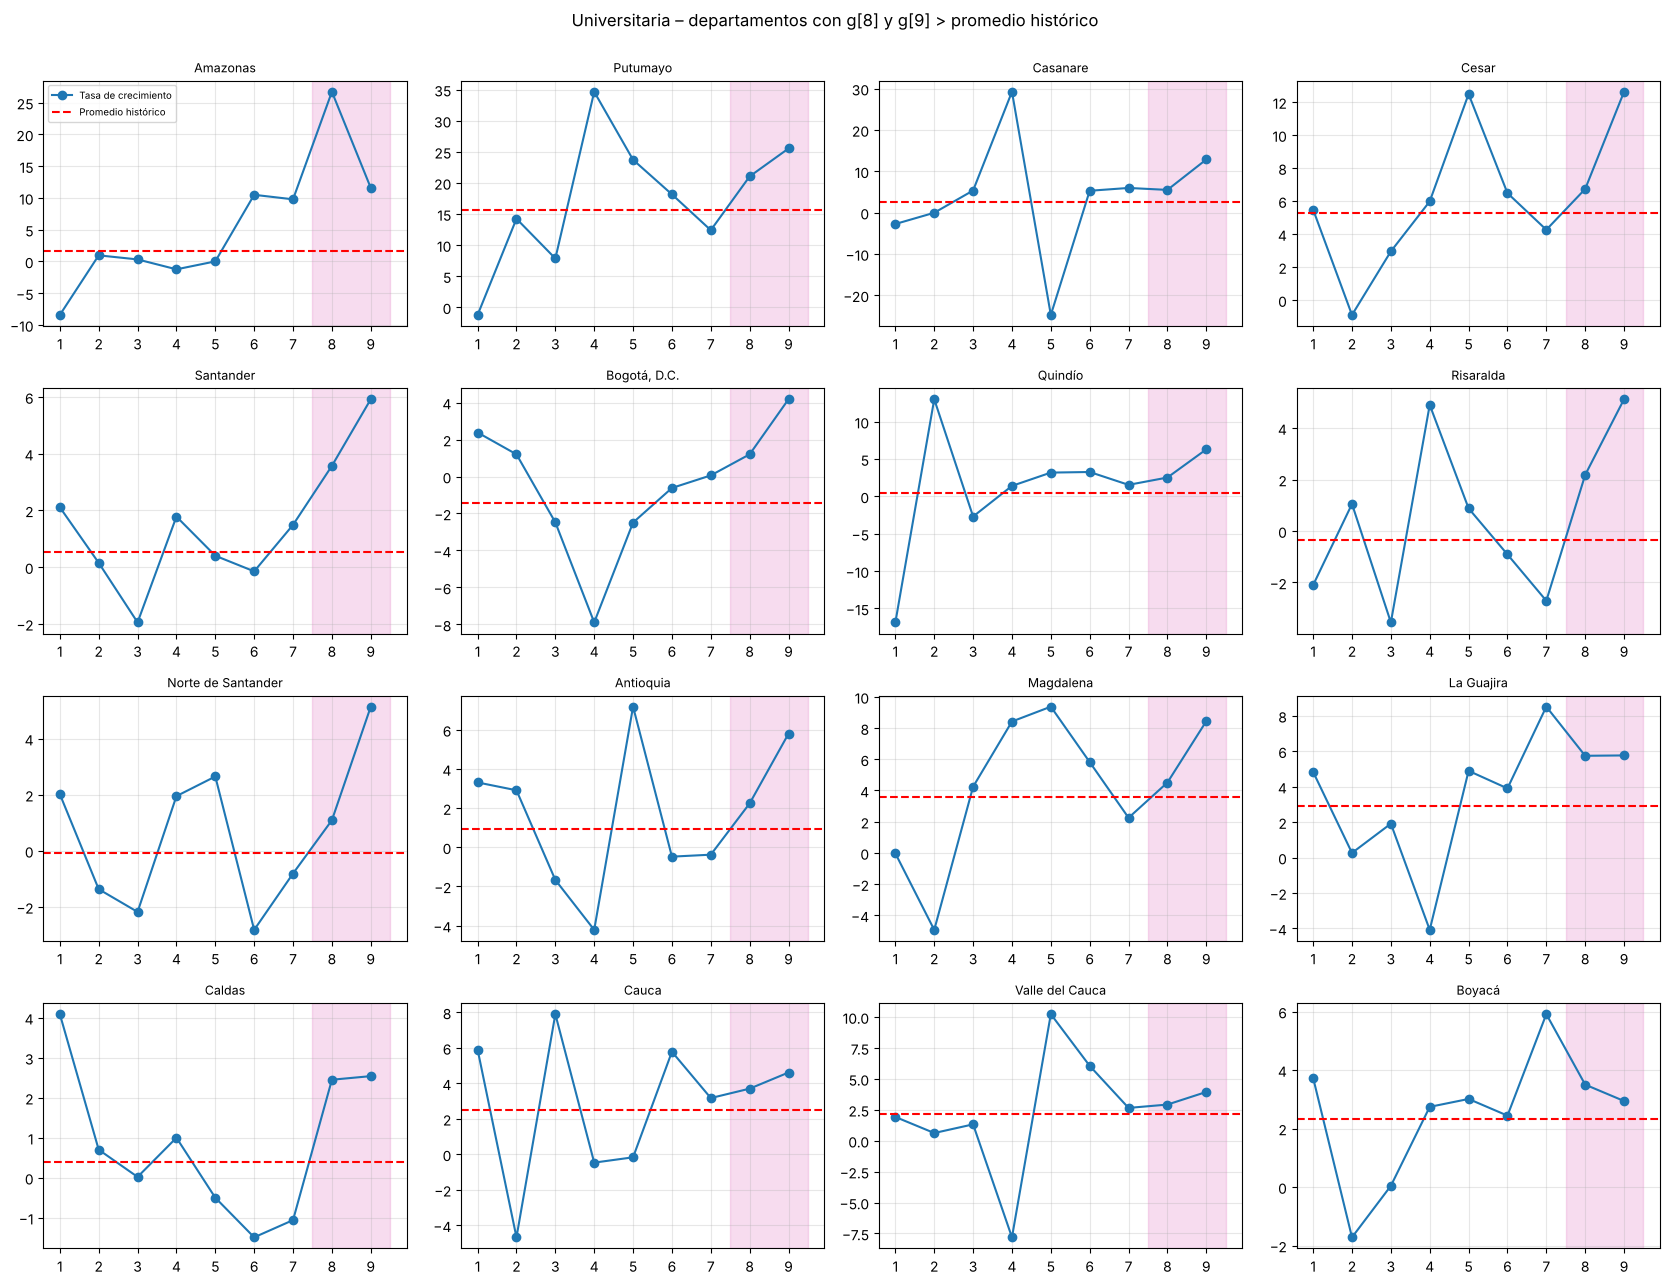

In [6]:
graficar_top("universitaria"); graficar_todos("universitaria")

## Comparación antes y después de 2023

In [7]:
antes_despues = (ds2.assign(antes=ds2[HIST].mean(axis=1), despues=ds2[[P8, P9]].mean(axis=1))
                 .groupby("nivel")[["antes", "despues"]].agg(["mean", "median"]).round(2))
antes_despues

antes        despues       
                mean median    mean median
nivel                                     
tecnica        31.15   1.83  118.28  10.22
tecnologica    -3.21  -3.87    4.84   3.21
universitaria   5.86   2.61    5.60   3.65

## Datos de apoyo para interpretar los resultados
Las tasas dependen del tamaño de la base: una tasa alta con pocas decenas de estudiantes dice poco. Por eso se añade la matrícula de 2023 y 2025 (de `snies_raw.csv`) a cada caso seleccionado y se marca como *base pequeña* a los que partían de menos de 500 estudiantes.

In [8]:
raw = pd.read_csv("snies_raw.csv")
NIVELES = ["tecnica", "tecnologica", "universitaria"]

def matricula(dep, nivel, anio):
    return int(raw[(raw["departamento"] == dep) & (raw["año"] == anio)][nivel].iloc[0])

sel["mat_2023"] = [matricula(r.departamento, r.nivel, 2023) for r in sel.itertuples()]
sel["mat_2025"] = [matricula(r.departamento, r.nivel, 2025) for r in sel.itertuples()]
sel["aumento_2023_2025"] = sel["mat_2025"] - sel["mat_2023"]
sel["base_pequena"] = sel["mat_2023"] < 500

print("Casos seleccionados con base < 500 estudiantes en 2023:", int(sel["base_pequena"].sum()), "de", len(sel))
print("\nAumento absoluto de matrícula 2023→2025 sumando los casos seleccionados:")
display(sel.groupby("nivel")["aumento_2023_2025"].sum().to_frame("estudiantes_adicionales"))
print("Departamentos seleccionados en los tres niveles:")
conteo = sel.groupby("departamento").size()
print(sorted(conteo[conteo == 3].index))
display(sel.sort_values("dif_media", ascending=False).head(10))

Casos seleccionados con base < 500 estudiantes en 2023: 7 de 45

Aumento absoluto de matrícula 2023→2025 sumando los casos seleccionados:


,estudiantes_adicionales
nivel,
tecnica,7122
tecnologica,22857
universitaria,89682


Departamentos seleccionados en los tres niveles:
['Amazonas', 'Caldas', 'Risaralda', 'Santander', 'Valle del Cauca']


,departamento,nivel,prom_hist,tasa_2023_2024,tasa_2024_2025,dif_2023_2024,dif_2024_2025,dif_media,mat_2023,mat_2025,aumento_2023_2025,base_pequena
0,Amazonas,tecnica,-44.76,-3.33,72.41,41.43,117.17,79.30,30,50,20,True
1,Nariño,tecnica,-12.16,-0.63,57.59,11.53,69.75,40.64,159,249,90,True
8,Arauca,tecnologica,-7.00,7.31,37.04,14.31,44.04,29.17,561,825,264,False
2,Córdoba,tecnica,-0.76,41.03,6.24,41.79,7.00,24.39,602,902,300,False
9,Vaupés,tecnologica,-11.17,-8.51,25.58,2.66,36.75,19.71,47,54,7,True
3,Caldas,tecnica,10.01,36.97,21.93,26.96,11.92,19.44,3616,6039,2423,False
4,Huila,tecnica,-4.32,16.86,12.44,21.18,16.76,18.97,516,678,162,False
10,Vichada,tecnologica,-9.86,14.74,3.35,24.60,13.21,18.91,312,370,58,True
5,Santander,tecnica,-4.72,3.38,24.73,8.10,29.45,18.78,1420,1831,411,False
6,Valle del Cauca,tecnica,1.14,12.85,26.79,11.71,25.65,18.68,7761,11104,3343,False


In [9]:
# Agregado nacional por nivel (suma de los 33 territorios) y su variación interanual
nac = raw.groupby("año")[NIVELES].sum()
display(nac.pct_change().mul(100).round(2).rename_axis("año (variación vs. año anterior, %)"))

,tecnica,tecnologica,universitaria
"año (variación vs. año anterior, %)",,,
2016,NaN,NaN,NaN
2017,-11.29,3.16,2.33
2018,7.31,-4.20,0.59
2019,4.05,-8.91,-0.35
2020,-15.77,1.17,-1.44
2021,7.54,6.23,2.51
2022,12.01,-0.74,1.30
2023,9.45,-4.76,1.10
2024,5.01,5.14,1.95


In [10]:
# Sector oficial: variación interanual del porcentaje oficial (Dataset 3) antes y después de 2023
ds3 = pd.read_csv("dataset3.csv").set_index("departamento")
oficial = pd.DataFrame({
    "mediana ΔO (pp)": [ds3[HIST].stack().median(), ds3[P8].median(), ds3[P9].median()],
    "departamentos con ΔO > 0": [None, int((ds3[P8] > 0).sum()), int((ds3[P9] > 0).sum())],
}, index=["histórico (7 intervalos)", P8, P9]).round(2)
display(oficial)
print("Departamentos con ΔO > 0 en ambos intervalos posteriores:", int(((ds3[P8] > 0) & (ds3[P9] > 0)).sum()), "de", len(ds3))

,mediana ΔO (pp),departamentos con ΔO > 0
histórico (7 intervalos),0.5,NaN
2023_2024,1.5,25.0
2024_2025,1.4,29.0


Departamentos con ΔO > 0 en ambos intervalos posteriores: 22 de 33


## Exportación de la tabla de resultados

In [11]:
sel.to_csv("tarea5_seleccionados.csv", index=False)
print("Guardado tarea5_seleccionados.csv:", sel.shape)
pd.read_csv("tarea5_seleccionados.csv").head()

Guardado tarea5_seleccionados.csv: (45, 12)


,departamento,nivel,prom_hist,tasa_2023_2024,tasa_2024_2025,dif_2023_2024,dif_2024_2025,dif_media,mat_2023,mat_2025,aumento_2023_2025,base_pequena
0,Amazonas,tecnica,-44.76,-3.33,72.41,41.43,117.17,79.30,30,50,20,True
1,Nariño,tecnica,-12.16,-0.63,57.59,11.53,69.75,40.64,159,249,90,True
2,Córdoba,tecnica,-0.76,41.03,6.24,41.79,7.00,24.39,602,902,300,False
3,Caldas,tecnica,10.01,36.97,21.93,26.96,11.92,19.44,3616,6039,2423,False
4,Huila,tecnica,-4.32,16.86,12.44,21.18,16.76,18.97,516,678,162,False


## Preguntas de análisis

> Las cifras de esta sección provienen de las tablas de arriba (datos SNIES de la Tarea 1). Las referencias normativas están al final.

### 1. ¿Qué departamentos y niveles presentaron tasas superiores al promedio histórico en 2023–2024 y 2024–2025? ¿Cuáles tienen las mayores diferencias y por qué?

**Qué se observa.** De las 93 combinaciones departamento–nivel analizadas, **45 (48 %)** superaron su promedio histórico en *los dos* intervalos posteriores: **8 de 27** en técnica profesional (30 %), **21 de 33** en tecnológica (64 %) y **16 de 33** en universitaria (48 %). La tecnológica es el nivel donde el cambio es más generalizado.

**Mayores diferencias (diferencia media con el promedio histórico, en puntos porcentuales):**
- *Técnica profesional:* Amazonas (+79,3), Nariño (+40,6), Córdoba (+24,4), Caldas (+19,4).
- *Tecnológica:* Arauca (+29,2), Vaupés (+19,7), Vichada (+18,9), La Guajira (+16,5), Atlántico (+16,1).
- *Universitaria:* Amazonas (+17,4), Putumayo (+7,6), Casanare (+6,6), Cesar (+4,4), Santander (+4,2), Bogotá (+4,1).

**Posibles razones.**
1. **Bases pequeñas.** Las mayores diferencias se concentran en territorios con muy pocos estudiantes: Amazonas en técnica profesional pasó de 30 a 50 estudiantes entre 2023 y 2025, y Vaupés en tecnológica de 47 a 54. En total, 7 de los 45 casos partían de menos de 500 estudiantes. En estos casos pocos estudiantes mueven mucho la tasa, y la diferencia grande no implica un cambio sustancial.
2. **Promedios históricos bajos o negativos.** En tecnológica la mediana de los promedios históricos departamentales es −3,9 % (a nivel nacional la matrícula tecnológica cayó en 4 de los 7 intervalos previos). Superar el promedio puede significar solo "dejar de caer": Amazonas en técnica profesional tuvo −3,3 % en 2023–2024 y aun así supera su promedio histórico de −44,8 %.
3. **Casos con mayor peso real.** Sumando los casos seleccionados, la matrícula adicional entre 2023 y 2025 fue de unos 89.700 estudiantes en universitaria (Bogotá +24.858, Cesar +7.023, Santander +6.848), 22.900 en tecnológica (Atlántico +5.722) y 7.100 en técnica profesional (Caldas +2.423).
4. **Cambio generalizado en algunos territorios.** Amazonas, Caldas, Risaralda, Santander y Valle del Cauca superan su promedio en los tres niveles, lo que sugiere un cambio más amplio y menos atribuible a ruido de un solo nivel.
5. **Contexto nacional.** Sumando los 33 territorios, la matrícula tecnológica creció 5,1 % en 2023–2024 y 10,4 % en 2024–2025 (el mayor valor de toda la serie; el máximo previo fue 6,2 %) y la universitaria 2,0 % y 4,6 % (también el mayor valor de la serie; el máximo previo fue 2,5 %).

### 2. ¿En qué medida los cambios podrían estar relacionados con la Ley 2307 de 2023? Alcance de la ley y otros factores

**Alcance de la ley.** La ley (sancionada el 31 de julio de 2023) obliga al Gobierno a financiar la gratuidad de la **matrícula de pregrado** en **instituciones de educación superior públicas** (técnicas, tecnológicas y universitarias según la Ley 30 de 1992). Es **progresiva y sujeta a disponibilidad presupuestal**, con priorización de población vulnerable, y su financiación debe venir de recursos adicionales de la Nación. Su reglamentación (Decreto 2271 del 29 de diciembre de 2023) permitió implementarla desde el **primer semestre de 2024**. Por eso 2023–2024 es el primer intervalo en que podría verse un efecto, y el dato anual de 2024 usa precisamente el semestre 1.

**Elementos consistentes con un efecto de la ley.**
- *Temporalidad:* el aumento en tecnológica y universitaria coincide con los dos intervalos en que la política ya operaba. A nivel nacional, ambos niveles tuvieron en 2025 su mayor crecimiento de la serie.
- *Sector oficial:* la mediana de la variación del porcentaje oficial fue de +0,5 pp en el histórico y subió a +1,5 pp (2023–2024) y +1,4 pp (2024–2025); 22 de 33 departamentos tuvieron variación positiva en ambos intervalos. Esto es coherente con una política que reduce el costo de la matrícula pública.
- *Evidencia regional externa:* el Ministerio de Educación reporta 21.725 estudiantes adicionales en primer semestre en universidades públicas del Caribe entre 2023 y 2024.

**Límites: por qué no se puede afirmar causalidad.**
1. **La gratuidad ya existía para buena parte de los estudiantes.** Antes de la ley hubo políticas de gratuidad focalizada (Matrícula Cero, Generación E, Ley 2155 y Decreto 1667 de 2021). Según el Ministerio, en 2023 ya recibían gratuidad 688 mil de 843 mil estudiantes de pregrado público (82 %), de modo que el efecto marginal de la ley sobre la matrícula debería ser menor al que sugiere su nombre. El salto del porcentaje oficial de Bogotá en 2021 (de 30,7 % a 40,7 %) coincide con esa etapa previa, lo que sugiere que el sector oficial ya venía cambiando por otras políticas (hipótesis que conviene verificar).
2. **La ley solo cubre pregrado público, y el análisis usa matrícula total.** Cada tasa mezcla instituciones públicas y privadas, y la gratuidad no cubre costos de sostenimiento (que dependen de apoyos adicionales y de disponibilidad presupuestal). Además, el SENA pesa mucho en el sector oficial y en los niveles técnico y tecnológico, y el texto de la ley no lo menciona; conviene verificar si queda cubierto antes de atribuirle a la ley su comportamiento.
3. **Otros factores.** La recuperación posterior a la pandemia (caídas de 2020), la dinámica demográfica, el desempleo y las condiciones económicas, la ampliación de oferta y sedes regionales (estrategia "Universidad en tu Territorio") y cambios institucionales pueden explicar parte de los aumentos.
4. **Límites estadísticos.** Se comparan solo dos intervalos frente a un promedio de siete, sin grupo de control ni prueba de significancia. Superar el promedio no implica un aumento estadísticamente significativo, y las bases pequeñas hacen que las tasas sean muy volátiles.

**Conclusión.** Los resultados son **compatibles** con que la gratuidad haya impulsado la matrícula, sobre todo en tecnológica y universitaria y en el sector oficial, pero **no lo demuestran**: coinciden en el tiempo con otras políticas y factores. Para fortalecer la conclusión se podría separar la matrícula pública de la privada por nivel y comparar su evolución (diferencias en diferencias), y evaluar si la diferencia con el promedio supera la variabilidad histórica de cada serie.

### Fuentes normativas e institucionales
- Texto de la Ley 2307 de 2023: https://jurinfo.jep.gov.co/Normograma/Compilacion/docs/ley_2307_2023.htm
- Ministerio de Educación, ABC de la política de gratuidad 2024-1 (Decreto 2271 de 2023): https://www.mineducacion.gov.co/1780/w3-article-419531.html
- Ministerio de Educación, "Universidad en tu Territorio" (cifras 2023): https://www.mineducacion.gov.co/1780/w3-article-420935.html
- Ministerio de Educación, información de interés de la política de gratuidad (Caribe 2023–2024): https://www.mineducacion.gov.co/portal//419532:Informacion-de-Interes-Politica-de-Gratuidad
- Ministerio de Educación, gratuidad gradual (Ley 2155 y Decreto 1667 de 2021): https://www.mineducacion.gov.co/1780/articles-427292_pdf.pdf